# 1. Model building

Explores the housing data, compares several models and shows how well the best one does on houses it never saw.

**The data is made up.** It comes from `house_price/generate_data.py`, so nothing here describes real house prices.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from house_price.config import RAW_DATA
from house_price.train import train_models

%matplotlib inline

## Look at the data

In [3]:
data = pd.read_csv(RAW_DATA)
print(f"{len(data)} houses")
data.head()

2000 houses


,area,bedroom,bathroom,age,locality,price
0,2260,3.0,3,19.0,Old Town,7918000
1,1320,2.0,2,8.0,Hillcrest,6795000
2,2700,4.0,4,2.0,Riverview,16424000
3,2910,4.0,4,30.0,Lakeside,16974000
4,920,1.0,1,16.0,Riverview,3720000


In [4]:
data.describe().round(1)

,area,bedroom,bathroom,age,price
count,2000.0,1948.0,2000.0,1964.0,2000.0
mean,2115.8,3.1,2.6,11.5,11010326.5
std,868.5,1.2,1.2,10.5,5594193.7
min,600.0,1.0,1.0,0.0,1915000.0
25%,1500.0,2.0,2.0,3.0,7050000.0
50%,1980.0,3.0,3.0,8.0,9736500.0
75%,2540.0,4.0,3.0,16.0,13482750.0
max,6000.0,6.0,5.0,40.0,41786000.0


A few bedroom and age values are missing on purpose. The model fills them with the median of the training houses, inside the pipeline, so test houses can't influence it.

In [5]:
data.isna().sum()

area         0
bedroom     52
bathroom     0
age         36
locality     0
price        0
dtype: int64

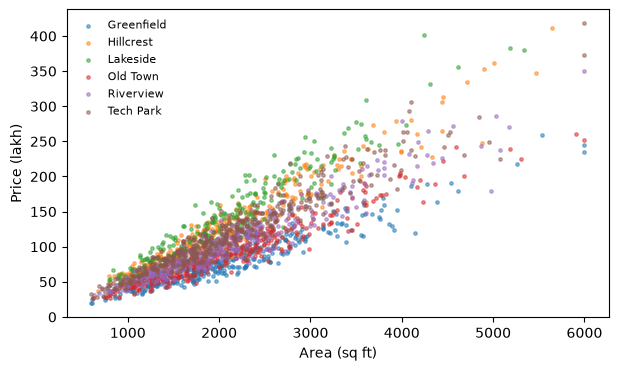

In [6]:
fig, axis = plt.subplots(figsize=(7, 4))
for locality, part in data.groupby("locality"):
    axis.scatter(part["area"], part["price"] / 100_000, s=6, alpha=0.5, label=locality)
axis.set_xlabel("Area (sq ft)")
axis.set_ylabel("Price (lakh)")
axis.legend(frameon=False, fontsize=8)
plt.show()

## Compare models

Models are chosen by 5-fold cross-validation on the training houses. The test houses are only used for the final score. The baseline always guesses the median price, so a useful model has to beat it.

In [7]:
result = train_models(data)

comparison = pd.DataFrame(result.test_scores).T
comparison["cv_mae"] = pd.Series(result.cv_mae)
comparison.sort_values("cv_mae").round(3)

,mae,rmse,r2,mape,cv_mae
ridge_log_price,713005.15,1036803.63,0.967,0.064,719351.44
gradient_boosting,775919.01,1173928.05,0.958,0.072,893425.39
random_forest,801283.73,1194677.06,0.956,0.074,917173.04
ridge,1083853.82,1488221.65,0.932,0.117,1036796.35
linear_regression,1084799.19,1488286.08,0.932,0.117,1038368.11
baseline_median,4081950.00,5845387.67,-0.053,0.410,4121369.38


In [8]:
print("Chosen model:", result.best_name)
scores = result.test_scores[result.best_name]
print(f"Average error on unseen houses: {scores['mae'] / 100_000:.1f} lakh ({scores['mape']:.1%})")
print(f"R2 on unseen houses: {scores['r2']:.3f}")

Chosen model: ridge_log_price
Average error on unseen houses: 7.1 lakh (6.4%)
R2 on unseen houses: 0.967


## Check the predictions

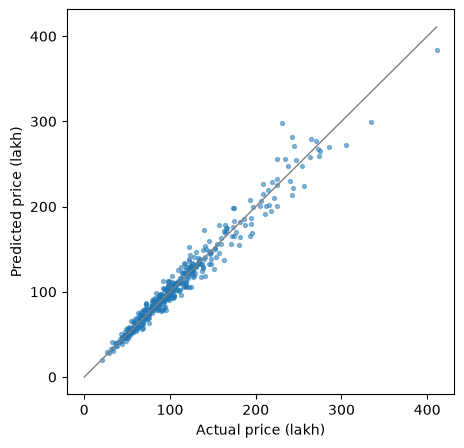

In [9]:
predicted = result.models[result.best_name].predict(result.X_test)

fig, axis = plt.subplots(figsize=(5, 5))
axis.scatter(result.y_test / 100_000, predicted / 100_000, s=8, alpha=0.5)
limit = max(result.y_test.max(), predicted.max()) / 100_000
axis.plot([0, limit], [0, limit], color="grey", linewidth=1)
axis.set_xlabel("Actual price (lakh)")
axis.set_ylabel("Predicted price (lakh)")
plt.show()

## What these results mean

The log-price model does best partly because the made-up prices were generated by multiplying factors together, which is exactly the shape that model assumes. Real house prices would be messier, so expect real-world accuracy to be lower.

This notebook doesn't save anything. To produce the saved model and reports, run `python -m house_price.train`.